# CS604 Colab launcher — Ana: Van's full FT recipe at 336

Runtime: **A100 40GB GPU**, High-RAM off. Images stay on Colab disk (`/content/data`). Checkpoints and logs go to the shared Drive folder **CS604_RUNS**.

The GitHub repo is private, so the clone cell will ask for a Personal Access Token (hidden). Do not paste the token into the notebook text or commit it.

**Drive:** everyone must have `CS604_RUNS` under *My Drive* (create it there, or open the [shared folder](https://drive.google.com/drive/folders/107nc4GKekmaKe38GR_8VBn3Bh_xH-ZtR) → Organize → **Add shortcut to Drive** → My Drive, name it `CS604_RUNS`). A Drive *link* is not a file path Colab can write to.

A copy of `van_colab_launcher.ipynb` running Van's recipe at 336 (`configs/full_ft_336px_proto-cosine_llrd0.75_top-lr4e-4_2.4h.yaml`, branch `ana-branch`) to compare with her 0.757 at 224. Only the settings cell and the prototype cell (built at 336) differ from hers. As in Van's launcher:

- `BRANCH`, `METHOD` and `TEAM` are already set.
- Prediction finds the run folder that training just created and writes `val_team_{TEAM}.txt` and `.zip` inside it (not in the shared `CS604_RUNS` root). It skips the test split until test data is released.
- With `AUTO_DISCONNECT = True`, the runtime ends after the last cell, or as soon as training fails, so an idle GPU does not keep using compute units. Drive is flushed first.

Use **Runtime → Run all**.

In [1]:
REPO_URL = "https://github.com/keaidewoq/cs604-project.git"
REPO_DIR = "/content/repo"
DATA_DIR = "/content/data"
# Must match a folder (or shortcut) in My Drive — not the browser URL.
DRIVE_OUT = "/content/drive/MyDrive/CS604_RUNS"
BRANCH = "ana-branch"
METHOD = "full_ft_336px_proto-cosine_llrd0.75_top-lr4e-4_2.4h"  # configs/<METHOD>.yaml
TEAM = "08"
PROTO_PT = f"{DRIVE_OUT}/prototypes_336.pt"  # must match the config's prototype_file
# End the runtime after the last cell, or as soon as training fails.
AUTO_DISCONNECT = True


def end_runtime(reason):
    """Flush Drive writes, then release the GPU so it stops using compute units."""
    print(reason, flush=True)
    if not AUTO_DISCONNECT:
        return
    from google.colab import drive, runtime
    try:
        drive.flush_and_unmount()  # without this the last checkpoint can be lost
        print("Drive flushed and unmounted", flush=True)
    except Exception as error:
        print(f"Drive flush failed: {error}", flush=True)
    runtime.unassign()

## 1. Clone or pull the repo

In [2]:
import os
from getpass import getpass

token = getpass("GitHub PAT (hidden; repo scope). Leave empty if the repo is public: ")
clone_url = REPO_URL.replace("https://", f"https://{token}@") if token else REPO_URL

if os.path.isdir(os.path.join(REPO_DIR, ".git")):
    !git -C {REPO_DIR} fetch origin
    !git -C {REPO_DIR} checkout {BRANCH}
    if token:
        !git -C {REPO_DIR} pull {clone_url} {BRANCH}
    else:
        !git -C {REPO_DIR} pull origin {BRANCH}
else:
    !git clone -b {BRANCH} {clone_url} {REPO_DIR}

%cd {REPO_DIR}
!git branch --show-current
!git rev-parse --short HEAD

GitHub PAT (hidden; repo scope). Leave empty if the repo is public: ··········
Cloning into '/content/repo'...
remote: Enumerating objects: 842, done.
remote: Counting objects: 100% (842/842), done.
remote: Compressing objects: 100% (405/405), done.
remote: Total 842 (delta 462), reused 773 (delta 410), pack-reused 0 (from 0)
Receiving objects: 100% (842/842), 624.67 KiB | 14.20 MiB/s, done.
Resolving deltas: 100% (462/462), done.
/content/repo
ana-branch
aca102b


## 2. Install requirements

In [3]:
%pip install -r requirements.txt

## 3. Mount Drive and check `CS604_RUNS`

If this cell errors, add a shortcut named `CS604_RUNS` to My Drive from the [shared folder](https://drive.google.com/drive/folders/107nc4GKekmaKe38GR_8VBn3Bh_xH-ZtR).

In [4]:
from pathlib import Path

from google.colab import drive

drive.mount("/content/drive")

out = Path(DRIVE_OUT)
if not out.is_dir():
    raise FileNotFoundError(
        f"{DRIVE_OUT} not found after mounting.\n"
        "Open https://drive.google.com/drive/folders/107nc4GKekmaKe38GR_8VBn3Bh_xH-ZtR "
        "→ Organize → Add shortcut to Drive → My Drive, and name the shortcut CS604_RUNS."
    )
out.mkdir(parents=True, exist_ok=True)
print("Writing runs to", out.resolve())
print("Existing items:", [p.name for p in out.iterdir()][:20])

Mounted at /content/drive
Writing runs to /content/drive/.shortcut-targets-by-id/107nc4GKekmaKe38GR_8VBn3Bh_xH-ZtR/CS604_RUNS
Existing items: ['prototypes.pt', 'prototypes.json', 'full_ft_20261005_074553_id962394', 'full_ft_20261006_031830', 'headinit_full_ft_336_20261006_110343']


## 4. Download data to `/content/data`

In [5]:
!python scripts/download_data.py --dest {DATA_DIR}

[download] snapshot doem1997/cs604-course-data -> /content/data
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0% 0/7 [00:00<?, ?it/s]Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.

Reconstructing (incomplete total...):   0% 0.00/1.71k [00:00<?, ?B/s]         

Fetching 7 files:  14% 1/7 [00:00<00:01,  3.80it/s]
Reconstructing (incomplete total...):   0% 1.71k/4.44G [00:00<188:54:17, 6.53kB/s]
Reconstructing (incomplete total...):   0% 1.71k/4.47G [00:00<190:06:28, 6.53kB/s]
Reconstructing (incomplete total...):   0% 1.71k/44.6G [00:00<1895:30:20, 6.53kB/s]
Reconstructing (incomplete total...):   0% 1.71k/44.6G [00:00<1895:30:20, 6.53kB/s]
Reconstructing (incomplete total...):   0% 4.22k/44.6G [00:00<1895:33:01, 6.53kB/s]
Reconstructing (incomplete total...):   0% 29.4M/44.6G [00:01<44:13, 16.8MB/s]     

Reconstructing (incomplete total...):  

## 4b. Build class prototypes at 336 (once)

Same as Van's prototype head, but built from 336 features (built with `configs/{METHOD}.yaml`, so at its `img_size`). Run **once**; about 20–25 min on an A100. Takes a while (embeds train images). Skip if the file already exists on Drive.

In [6]:
from pathlib import Path

if Path(PROTO_PT).is_file():
    print("Already have", PROTO_PT)
else:
    !python scripts/build_prototypes.py --config configs/{METHOD}.yaml --data_root {DATA_DIR} --output {PROTO_PT}


model.safetensors: downloading bytes:   0% 0.00/346M [00:00<?, ?B/s]
model.safetensors: downloading bytes:  16% 56.2M/346M [00:02<00:05, 57.2MB/s, 3.43MB/s  ]
model.safetensors: reconstructing file:   0% 591k/346M [00:02<17:10, 336kB/s, 5.54kB/s  ]
model.safetensors: downloading bytes:  21% 73.8M/346M [00:02<00:04, 66.3MB/s, 6.31MB/s  ]
model.safetensors: downloading bytes:  35% 120M/346M [00:02<00:02, 91.2MB/s, 9.65MB/s  ] 
model.safetensors: downloading bytes:  39% 136M/346M [00:02<00:02, 89.0MB/s, 11.5MB/s  ]
model.safetensors: downloading bytes:  44% 153M/346M [00:03<00:02, 86.6MB/s, 12.8MB/s  ]
model.safetensors: reconstructing file:  48% 165M/346M [00:03<00:01, 103MB/s, 13.9MB/s  ]
model.safetensors: downloading bytes:  49% 171M/346M [00:03<00:01, 87.8MB/s, 14.0MB/s  ]
model.safetensors: downloading bytes:  55% 190M/346M [00:03<00:01, 90.3MB/s, 15.5MB/s  ]
model.safetensors: downloading bytes:  61% 213M/346M [00:03<00:01, 96.8MB/s, 16.8MB/s  ]
model.safetensors: downloading byte

## Review settings (table)

Loads `configs/{METHOD}.yaml` (merged with `shared_vit-b16_augreg2_defaults.yaml`) so you can check every parameter before spending a GPU hour.

In [7]:
import pandas as pd

from src.utils import apply_overrides, load_config

methods = ["full_ft", "linear_probe", "lora_r8_224px_lr1e-3_5epoch", "bitfit", "last_blocks", "class-prototypes_augreg2_224px_cosine-head", "lora_r8_224px_proto-cosine-head", "adapter", "adaptformer"]
merged = {name: load_config(f"configs/{name}.yaml").to_dict() for name in methods}
keys = []
for d in merged.values():
    for k in d:
        if k not in keys:
            keys.append(k)

compare = pd.DataFrame(
    {name: [merged[name].get(k, "") for k in keys] for name in methods},
    index=keys,
)
compare.index.name = "parameter"
print("Resolved parameters per method (shared_vit-b16_augreg2_defaults.yaml already merged in):")
display(compare)

chosen = load_config(f"configs/{METHOD}.yaml")
apply_overrides(chosen, data_root=DATA_DIR, output_dir=DRIVE_OUT)
resolved = pd.DataFrame(list(chosen.to_dict().items()), columns=["parameter", "value"])
print(f"\nThis run (METHOD={METHOD!r}, plus Colab data_root / output_dir):")
display(resolved)

Resolved parameters per method (shared_vit-b16_augreg2_defaults.yaml already merged in):


,full_ft,linear_probe,lora_r8_224px_lr1e-3_5epoch,bitfit,last_blocks,class-prototypes_augreg2_224px_cosine-head,lora_r8_224px_proto-cosine-head,adapter,adaptformer
parameter,,,,,,,,,
data_root,/content/data,/content/data,/content/data,/content/data,/content/data,/content/data,/content/data,/content/data,/content/data
model_name,vit_base_patch16_224.augreg2_in21k_ft_in1k,vit_base_patch16_224.augreg2_in21k_ft_in1k,vit_base_patch16_224.augreg2_in21k_ft_in1k,vit_base_patch16_224.augreg2_in21k_ft_in1k,vit_base_patch16_224.augreg2_in21k_ft_in1k,vit_base_patch16_224.augreg2_in21k_ft_in1k,vit_base_patch16_224.augreg2_in21k_ft_in1k,vit_base_patch16_224.augreg2_in21k_ft_in1k,vit_base_patch16_224.augreg2_in21k_ft_in1k
pretrained,True,True,True,True,True,True,True,True,True
num_classes,10000,10000,10000,10000,10000,10000,10000,10000,10000
img_size,224,224,224,224,224,224,224,224,224
batch_size,32,64,64,64,64,64,64,64,64
grad_accum_steps,2,1,1,1,1,1,1,1,1
epochs,2,5,5,5,3,5,5,5,5
lr,0.0001,0.001,0.001,0.001,0.0001,0.001,0.001,0.001,0.001



This run (METHOD='full_ft_336px_proto-cosine_llrd0.75_top-lr4e-4_2.4h', plus Colab data_root / output_dir):


,parameter,value
0,data_root,/content/data
1,model_name,vit_base_patch16_224.augreg2_in21k_ft_in1k
2,pretrained,True
3,num_classes,10000
4,img_size,336
5,batch_size,128
6,grad_accum_steps,2
7,epochs,30
8,lr,0.0004
9,weight_decay,0.05


## 5. Train (checkpoints on Drive)

In [8]:
import subprocess
import sys
import time

TRAIN_STARTED = time.time()
proc = subprocess.Popen(
    [sys.executable, "-u", "-m", "src.train", "--config", f"configs/{METHOD}.yaml",
     "--data_root", DATA_DIR, "--output_dir", DRIVE_OUT],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
)
for line in proc.stdout:
    print(line, end="", flush=True)
if proc.wait() != 0:
    end_runtime(f"training failed (exit {proc.returncode}); see the output above")
    raise SystemExit("training failed")

Streaming output truncated to the last 5000 lines.
epoch 8/30: 100%|██████████| 3515/3515 [16:57<00:00,  3.46it/s, loss=1.8850, lr=3.69e-06]
[epoch 8] train_loss=1.8974 (no labeled val)

epoch 9/30:  49%|████▉     | 1731/3515 [08:22<08:37,  3.45it/s, loss=1.8030, lr=1.21e-12]
[epoch 9] train_loss=1.8716 (no labeled val)
[train] time limit reached after 144.00 training minutes
[end] trainable=93.67M/93.67M (100.00%) wall_s=8653.2 gpu_hours=2.4037 peak_vram_gb=20.052
[train] done. checkpoints in /content/drive/MyDrive/CS604_RUNS/full_ft_20261006_122039


## 6. Predict

Uses the newest run folder created since training started; set `RUN_NAME` by hand only to predict from an older run. Uses `last.pt`: this config trains on all images, so there is no labelled validation and no `best.pt`. Writes `val_team_{TEAM}.txt` and `.zip` into the run folder.

In [9]:
import shutil
from pathlib import Path

RUN_NAME = None  # None: the run folder training just created
if RUN_NAME is None:
    started = globals().get("TRAIN_STARTED", 0)
    runs = [p for p in Path(DRIVE_OUT).iterdir() if p.is_dir() and p.stat().st_mtime >= started
            and (p / "config.yaml").is_file()]
    assert runs, "No run folder from this session; set RUN_NAME by hand"
    RUN_NAME = max(runs, key=lambda p: p.stat().st_mtime).name
RUN_DIR = Path(DRIVE_OUT) / RUN_NAME
CKPT = RUN_DIR / "last.pt"
assert CKPT.is_file(), f"Checkpoint missing: {CKPT}"
print("Predicting from", CKPT)

!python -m src.predict --config {RUN_DIR}/config.yaml --ckpt {CKPT} --split val --team {TEAM} --data_root {DATA_DIR} --out_dir {RUN_DIR}
shutil.make_archive(str(RUN_DIR / f"val_team_{TEAM}"), "zip", root_dir=RUN_DIR, base_dir=f"val_team_{TEAM}.txt")
print("Submit:", RUN_DIR / f"val_team_{TEAM}.zip")
if (Path(DATA_DIR) / "test.txt").is_file() and (Path(DATA_DIR) / "test").is_dir():
    !python -m src.predict --config {RUN_DIR}/config.yaml --ckpt {CKPT} --split test --team {TEAM} --data_root {DATA_DIR} --out_dir {RUN_DIR}
else:
    print("Test data not available; skipping test prediction.")

Predicting from /content/drive/MyDrive/CS604_RUNS/full_ft_20261006_122039/last.pt
predict val: 100% 391/391 [01:25<00:00,  4.59it/s]
[predict] wrote /content/drive/MyDrive/CS604_RUNS/full_ft_20261006_122039/val_team_08.txt (50000 lines; crop_pct=model default, tta_flip=False)
Submit: /content/drive/MyDrive/CS604_RUNS/full_ft_20261006_122039/val_team_08.zip
Test data not available; skipping test prediction.


## 6b. Predict with a tighter eval crop and flip averaging (optional)

Same checkpoint; only inference changes: center crop 0.7 instead of the model's 0.9, and the softmax averaged over the image and its horizontal flip (twice the inference compute). On Van's internal holdout this added +1.5 to +1.9 points for the 3- and 6-epoch laptop runs (training's random-resized crops zoom in, so a tighter test crop matches them). Writes a second submission to `tta_crop070_flip/` inside the run folder; the plain one above is unchanged. Set `TTA = False` to skip.

In [10]:
TTA = True
if TTA:
    TTA_DIR = RUN_DIR / "tta_crop070_flip"
    !python -m src.predict --config {RUN_DIR}/config.yaml --ckpt {CKPT} --split val --team {TEAM} --data_root {DATA_DIR} --out_dir {TTA_DIR} --crop_pct 0.7 --tta_flip
    shutil.make_archive(str(TTA_DIR / f"val_team_{TEAM}"), "zip", root_dir=TTA_DIR, base_dir=f"val_team_{TEAM}.txt")
    print("Submit (TTA):", TTA_DIR / f"val_team_{TEAM}.zip")
    if (Path(DATA_DIR) / "test.txt").is_file() and (Path(DATA_DIR) / "test").is_dir():
        !python -m src.predict --config {RUN_DIR}/config.yaml --ckpt {CKPT} --split test --team {TEAM} --data_root {DATA_DIR} --out_dir {TTA_DIR} --crop_pct 0.7 --tta_flip

predict val: 100% 391/391 [01:41<00:00,  3.86it/s]
[predict] wrote /content/drive/MyDrive/CS604_RUNS/full_ft_20261006_122039/tta_crop070_flip/val_team_08.txt (50000 lines; crop_pct=0.7, tta_flip=True)
Submit (TTA): /content/drive/MyDrive/CS604_RUNS/full_ft_20261006_122039/tta_crop070_flip/val_team_08.zip


## 7. Loss curves (from `colab_qq_train-one-config.ipynb`)

Plot the losses recorded during training, after training finishes. Save and display the plots in this experiment’s Drive folder. Validation curves require labeled validation.


full_ft_20261006_122039_epoch_loss.png


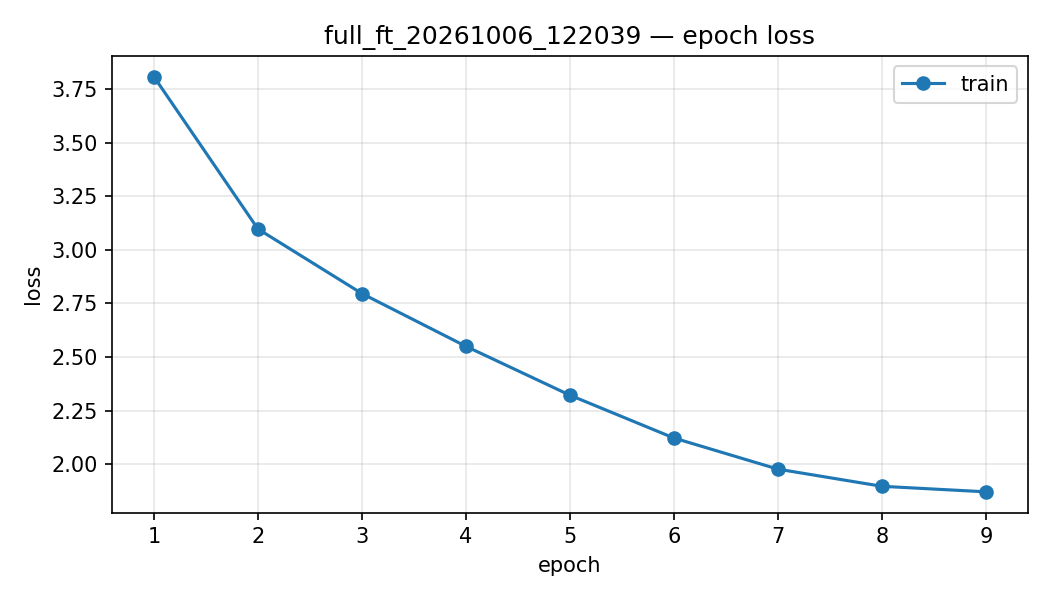

full_ft_20261006_122039_loss.png


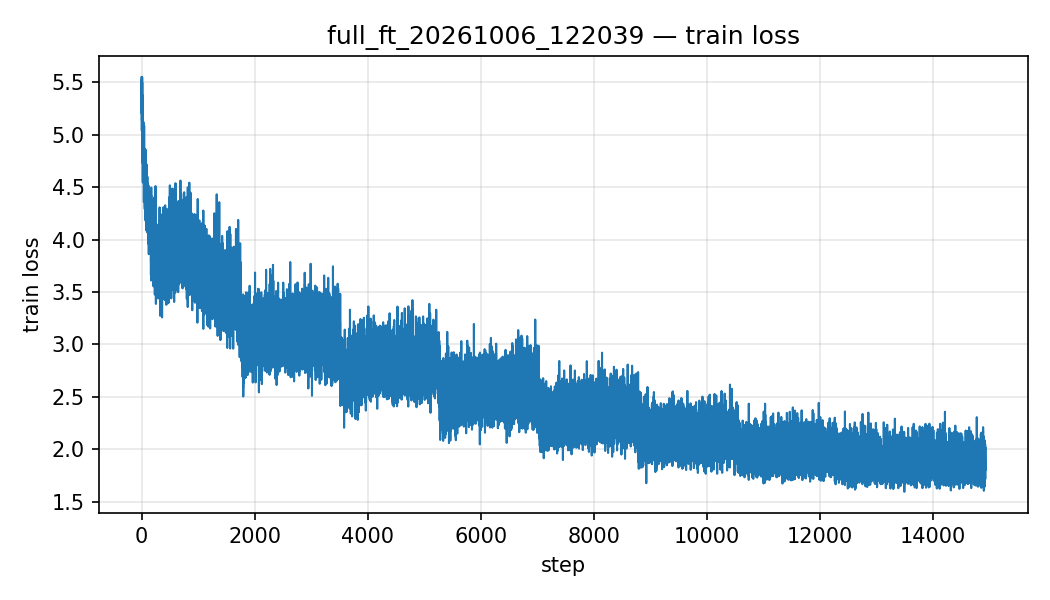

In [11]:
import subprocess

from IPython.display import display, Image

FIGURE_DIR = RUN_DIR / "figures"
subprocess.run([
    "python", "scripts/plot_curves.py",
    "--run_dir", str(RUN_DIR), "--out_dir", str(FIGURE_DIR),
], check=True)

for plot in sorted(FIGURE_DIR.glob("*.png")):
    print(plot.name)
    display(Image(filename=str(plot)))


## 8. Inference latency (from `colab_qq_train-one-config.ipynb`)

Load the trained checkpoint selected in section 6. Measure forward-pass latency on synthetic images at batch sizes 1 and 64, excluding preprocessing and transfers. Use 30 warm-ups and 200 timed iterations. Save results to `inference_latency.json`. This runs outside the training timer; keep GPU and measurement settings consistent between experiments.


In [12]:
import json
import torch

from src.utils import load_config, apply_overrides, set_seed
from src.model import build_model
from src.predict import load_checkpoint
from scripts.benchmark_latency import measure

assert torch.cuda.is_available(), "A GPU runtime is required."
cfg = load_config(RUN_DIR / "config.yaml")
# Partial PEFT checkpoints require the original pretrained backbone.
checkpoint_info = torch.load(CKPT, map_location="cpu", weights_only=False)
partial = bool(checkpoint_info.get("trainable_only", False))
del checkpoint_info
apply_overrides(cfg, pretrained=partial)
set_seed(int(cfg.seed))

device = torch.device("cuda")
model = build_model(cfg).to(device)
load_checkpoint(model, CKPT, device)
model.eval()

warmup = 30
iterations = 200
use_bf16 = bool(cfg.bf16)
results = {
    "checkpoint": str(CKPT),
    "gpu": torch.cuda.get_device_name(0),
    "gpu_capacity_GiB": torch.cuda.get_device_properties(0).total_memory / 1024**3,
    "torch_version": str(torch.__version__),
    "precision": "bf16" if use_bf16 else "fp32",
    "img_size": int(cfg.img_size),
    "warmup_iterations": warmup,
    "timed_iterations": iterations,
    "scope": "Forward pass on synthetic inputs; excludes loading, preprocessing and transfers",
    "measurements": [],
}

try:
    for batch_size in (1, 64):
        batch = torch.randn(
            batch_size, 3, int(cfg.img_size), int(cfg.img_size), device=device,
        )
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=use_bf16):
            ms_per_image, _ = measure(model, batch, device, warmup, iterations)
        results["measurements"].append({
            "batch_size": batch_size,
            "ms_per_image": ms_per_image,
            "ms_per_batch": ms_per_image * batch_size,
        })
        del batch
finally:
    del model
    torch.cuda.empty_cache()

output = RUN_DIR / "inference_latency.json"
output.write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))
print("Saved:", output)


{
  "checkpoint": "/content/drive/MyDrive/CS604_RUNS/full_ft_20261006_122039/last.pt",
  "gpu": "NVIDIA A100-SXM4-40GB",
  "gpu_capacity_GiB": 39.4935302734375,
  "torch_version": "2.11.0+cu130",
  "precision": "bf16",
  "img_size": 336,
  "warmup_iterations": 30,
  "timed_iterations": 200,
  "scope": "Forward pass on synthetic inputs; excludes loading, preprocessing and transfers",
  "measurements": [
    {
      "batch_size": 1,
      "ms_per_image": 7.93505816999641,
      "ms_per_batch": 7.93505816999641
    },
    {
      "batch_size": 64,
      "ms_per_image": 0.6367874727342837,
      "ms_per_batch": 40.75439825499416
    }
  ]
}
Saved: /content/drive/MyDrive/CS604_RUNS/full_ft_20261006_122039/inference_latency.json


## 9. End the runtime

Flushes Drive and releases the GPU when `AUTO_DISCONNECT = True`.

In [13]:
end_runtime("all cells finished; ending the runtime")

all cells finished; ending the runtime
Drive flushed and unmounted
